In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict
)
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

pd.set_option("display.max_columns", 100)

ROOT = Path.cwd()

if not (ROOT / "data").exists():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"

campaign = pd.read_csv(
    ROOT / "campaign_exposure.csv"
)

truth = pd.read_csv(
    ROOT / "simulation_truth.csv"
)

df = campaign.merge(
    truth,
    on="customer_id",
    how="left"
)

df["log_prior_spend_90d"] = np.log1p(
    df["prior_spend_90d"]
)

print(df.shape)

display(df.head())

(12000, 21)


,customer_id,region,acquisition_channel,tenure_months,loyalty_member,email_engagement_score,prior_orders_90d,prior_spend_90d,prior_units_90d,days_since_last_order,campaign_id,campaign_date,promotion_received,offer_discount_pct,purchased_30d,revenue_30d,true_treatment_propensity,true_purchase_prob_no_promo,true_purchase_prob_with_promo,true_individual_treatment_effect,log_prior_spend_90d
0,1,West,Paid Social,27,1,0.3692,1,494.69,3,10,AUG2026_REENGAGE,2026-08-01,1,20,1,64.05,0.641434,0.264710,0.300016,0.035306,6.205951
1,2,South,Paid Search,22,0,0.4690,1,42.38,1,26,AUG2026_REENGAGE,2026-08-01,0,0,0,0.00,0.520239,0.156707,0.217502,0.060795,3.769999
2,3,West,Organic,4,0,0.4790,0,0.00,0,365,AUG2026_REENGAGE,2026-08-01,1,20,0,0.00,0.178815,0.045118,0.136463,0.091345,0.000000
3,4,Midwest,Partner,32,1,0.6068,1,116.30,1,7,AUG2026_REENGAGE,2026-08-01,0,0,0,0.00,0.679241,0.359702,0.408076,0.048374,4.764735
4,5,Northeast,Organic,13,0,0.3126,0,0.00,0,365,AUG2026_REENGAGE,2026-08-01,0,0,0,0.00,0.147121,0.035954,0.118147,0.082193,0.000000


In [3]:
observed_summary = (
    df
    .groupby("promotion_received")
    .agg(
        customers=("customer_id", "count"),
        buyers=("purchased_30d", "sum"),
        purchase_rate=("purchased_30d", "mean"),
        avg_revenue_30d=("revenue_30d", "mean")
    )
)

display(observed_summary.round(4))

,customers,buyers,purchase_rate,avg_revenue_30d
promotion_received,,,,
0,7107,817,0.1150,13.3687
1,4893,1297,0.2651,31.5553


In [4]:
treated_rate = df.loc[
    df["promotion_received"] == 1,
    "purchased_30d"
].mean()

control_rate = df.loc[
    df["promotion_received"] == 0,
    "purchased_30d"
].mean()

naive_effect = treated_rate - control_rate

true_ate = (
    df["true_individual_treatment_effect"]
    .mean()
)

print(
    f"Naive treated-control difference: {naive_effect:.3f}"
)

print(
    f"True treatment effect: {true_ate:.3f}"
)

Naive treated-control difference: 0.150
True treatment effect: 0.071


The raw association substantially overstates the true promotional effect.

Why?

Promotion assignment was not random. Customers with stronger prior engagement,
loyalty, and purchasing behavior were more likely to receive the promotion.

The treated population was already different before treatment occurred.

In [5]:
categorical_features = [
    "region",
    "acquisition_channel"
]

numeric_features = [
    "tenure_months",
    "loyalty_member",
    "email_engagement_score",
    "prior_orders_90d",
    "log_prior_spend_90d",
    "prior_units_90d",
    "days_since_last_order"
]

feature_columns = (
    categorical_features
    + numeric_features
)

In [6]:
numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

In [7]:
treated_df = df[
    df["promotion_received"] == 1
].copy()

X_response = treated_df[
    feature_columns
]

y_response = treated_df[
    "purchased_30d"
]

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X_response,
    y_response,
    test_size=0.20,
    stratify=y_response,
    random_state=42
)

In [9]:
response_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LogisticRegression(
                max_iter=1000
            )
        )
    ]
)

response_model.fit(
    X_train,
    y_train
)

response_prob = (
    response_model
    .predict_proba(X_test)[:, 1]
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_test,
            response_prob
        ),
        3
    )
)

print(
    "PR-AUC:",
    round(
        average_precision_score(
            y_test,
            response_prob
        ),
        3
    )
)

ROC-AUC: 0.658
PR-AUC: 0.37


This model estimates which promoted customers are most likely to purchase.

It does **not** estimate whether the promotion caused those purchases.

A customer can have a high predicted response probability because they were already
likely to buy without treatment.

In [10]:
balance_features = [
    "email_engagement_score",
    "loyalty_member",
    "prior_orders_90d",
    "log_prior_spend_90d",
    "prior_units_90d",
    "days_since_last_order"
]

In [11]:
def standardized_mean_difference(
    data,
    feature,
    treatment_col="promotion_received"
):

    treated = data.loc[
        data[treatment_col] == 1,
        feature
    ]

    control = data.loc[
        data[treatment_col] == 0,
        feature
    ]

    pooled_sd = np.sqrt(
        (
            treated.var(ddof=1)
            + control.var(ddof=1)
        ) / 2
    )

    return (
        treated.mean() - control.mean()
    ) / pooled_sd

In [12]:
balance_before = pd.DataFrame({
    "feature": balance_features,
    "SMD_before": [
        standardized_mean_difference(
            df,
            feature
        )
        for feature in balance_features
    ]
})

balance_before[
    "abs_SMD_before"
] = balance_before[
    "SMD_before"
].abs()

display(
    balance_before
    .sort_values(
        "abs_SMD_before",
        ascending=False
    )
    .round(3)
)

,feature,SMD_before,abs_SMD_before
5,days_since_last_order,-0.881,0.881
3,log_prior_spend_90d,0.876,0.876
2,prior_orders_90d,0.733,0.733
4,prior_units_90d,0.661,0.661
0,email_engagement_score,0.383,0.383
1,loyalty_member,0.351,0.351


In [13]:
X_propensity = df[
    feature_columns
]

treatment = df[
    "promotion_received"
]

In [14]:
propensity_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LogisticRegression(
                max_iter=1000
            )
        )
    ]
)

In [15]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

propensity_scores = (
    cross_val_predict(
        propensity_model,
        X_propensity,
        treatment,
        cv=cv,
        method="predict_proba"
    )[:, 1]
)

In [16]:
df.shape

(12000, 21)

In [17]:
df["estimated_propensity"] = (
    propensity_scores
)

In [18]:
df[
    "estimated_propensity"
].describe(
    percentiles=[
        .01,
        .05,
        .25,
        .50,
        .75,
        .95,
        .99
    ]
)

,estimated_propensity
count,12000.000000
mean,0.407867
std,0.211458
min,0.085474
1%,0.113892
5%,0.137217
25%,0.206057
50%,0.370807
75%,0.608332
95%,0.732380


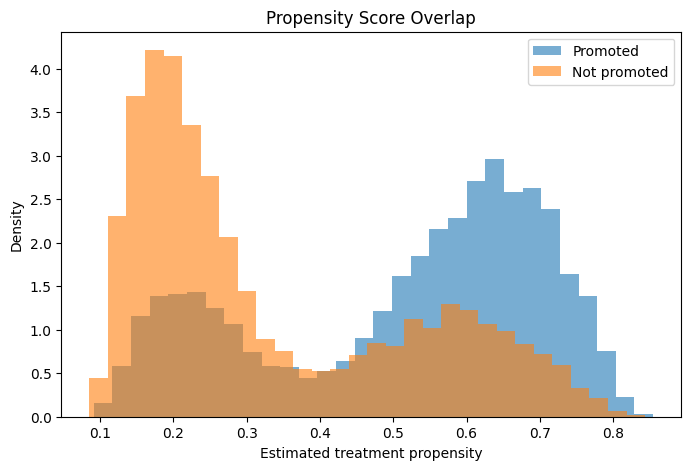

In [19]:
plt.figure(figsize=(8, 5))

plt.hist(
    df.loc[
        df["promotion_received"] == 1,
        "estimated_propensity"
    ],
    bins=30,
    alpha=0.6,
    density=True,
    label="Promoted"
)

plt.hist(
    df.loc[
        df["promotion_received"] == 0,
        "estimated_propensity"
    ],
    bins=30,
    alpha=0.6,
    density=True,
    label="Not promoted"
)

plt.xlabel(
    "Estimated treatment propensity"
)

plt.ylabel("Density")

plt.title(
    "Propensity Score Overlap"
)

plt.legend()

plt.show()

In [20]:
eps = 0.05

df["propensity_clipped"] = (
    df["estimated_propensity"]
    .clip(
        lower=eps,
        upper=1-eps
    )
)

In [21]:
treatment_rate = (
    df["promotion_received"]
    .mean()
)

In [22]:
treatment_rate

np.float64(0.40775)

In [23]:
# calculate inverse-propensity weight
df["ipw"] = np.where(
    df["promotion_received"] == 1,

    treatment_rate
    / df["propensity_clipped"],

    (1 - treatment_rate)
    / (
        1
        - df["propensity_clipped"]
    )
)

In [24]:
df["ipw"].describe(
    percentiles=[
        .01,
        .05,
        .50,
        .95,
        .99
    ]
)

,ipw
count,12000.000000
mean,1.002522
std,0.516954
min,0.477146
1%,0.522762
5%,0.567802
50%,0.769882
95%,2.127478
99%,2.823835
max,4.468404


In [25]:
treated_mask = (
    df["promotion_received"] == 1
)

control_mask = (
    df["promotion_received"] == 0
)

weighted_treated_mean = np.average(
    df.loc[
        treated_mask,
        "purchased_30d"
    ],
    weights=df.loc[
        treated_mask,
        "ipw"
    ]
)

weighted_control_mean = np.average(
    df.loc[
        control_mask,
        "purchased_30d"
    ],
    weights=df.loc[
        control_mask,
        "ipw"
    ]
)

ipw_ate = (
    weighted_treated_mean
    - weighted_control_mean
)

In [26]:
effect_comparison = pd.DataFrame({
    "Estimate": [
        "Naive observed difference",
        "IPW-adjusted ATE",
        "True simulated ATE"
    ],
    "Purchase Probability Effect": [
        naive_effect,
        ipw_ate,
        true_ate
    ]
})

display(
    effect_comparison.round(4)
)

,Estimate,Purchase Probability Effect
0,Naive observed difference,0.1501
1,IPW-adjusted ATE,0.0668
2,True simulated ATE,0.0712


Compare balance after inverse-propensity weighting

In [27]:
def weighted_mean(
    values,
    weights
):
    return np.average(
        values,
        weights=weights
    )


def weighted_variance(
    values,
    weights
):
    mean = weighted_mean(
        values,
        weights
    )

    return np.average(
        (values - mean) ** 2,
        weights=weights
    )


def weighted_smd(
    data,
    feature
):

    treated = data[
        data["promotion_received"] == 1
    ]

    control = data[
        data["promotion_received"] == 0
    ]

    mt = weighted_mean(
        treated[feature],
        treated["ipw"]
    )

    mc = weighted_mean(
        control[feature],
        control["ipw"]
    )

    vt = weighted_variance(
        treated[feature],
        treated["ipw"]
    )

    vc = weighted_variance(
        control[feature],
        control["ipw"]
    )

    pooled_sd = np.sqrt(
        (vt + vc) / 2
    )

    return (
        mt - mc
    ) / pooled_sd

In [28]:
balance_comparison = pd.DataFrame({
    "feature": balance_features,

    "SMD_before": [
        standardized_mean_difference(
            df,
            feature
        )
        for feature in balance_features
    ],

    "SMD_after_IPW": [
        weighted_smd(
            df,
            feature
        )
        for feature in balance_features
    ]
})

display(
    balance_comparison.round(3)
)

,feature,SMD_before,SMD_after_IPW
0,email_engagement_score,0.383,0.001
1,loyalty_member,0.351,-0.004
2,prior_orders_90d,0.733,-0.003
3,log_prior_spend_90d,0.876,-0.004
4,prior_units_90d,0.661,-0.004
5,days_since_last_order,-0.881,0.005
